# 04 - Evaluasi Final di TEST
Tujuan: mengukur model hasil notebook 03 pada **TEST (300 query)** dengan galeri = seluruh TRAIN (1050 gambar), lalu menganalisis hasilnya.

Aturan main:
- Konfigurasi sudah dikunci di notebook 03 (`artifacts/final_config.json`). **Jangan mengubah konfigurasi setelah melihat angka TEST.**
- Notebook ini hanya memuat model dan menghitung metrik, tidak ada training. Aman dijalankan ulang.
- Prasyarat: `final.pt`, `final_gallery.npy`, `final_gallery_manifest.csv`, `final_config.json` di folder `artifacts/`.

## 1. Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

DATA_DIR = Path("../data/raw")
MANIFEST = Path("../data/manifest.csv")
ART = Path("../artifacts")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE, BATCH, SEED = 224, 32, 42
np.random.seed(SEED)
print("device:", DEVICE)

device: cuda


## 2. Data dan konfigurasi final

In [2]:
EXT = {".jpg", ".jpeg", ".png"}

def build_manifest(data_dir):
    rows = []
    for split_dir in ["TRAIN", "TEST"]:
        for p in sorted((data_dir / split_dir).rglob("*")):
            if p.suffix.lower() in EXT:
                rows.append({"path": p.relative_to(data_dir).as_posix(),
                             "class": p.parent.name, "split": split_dir.lower()})
    return pd.DataFrame(rows)

df = pd.read_csv(MANIFEST)
classes = sorted(set(df["class"].tolist()))
cls2idx = {c: i for i, c in enumerate(classes)}

# galeri: urutan harus sama dengan final_gallery.npy
gallery_df = pd.read_csv(ART / "embeddings" / "final_gallery_manifest.csv")
test_df = df[df["split"] == "test"].reset_index(drop=True)
gl = gallery_df["class"].to_numpy()
ql = test_df["class"].to_numpy()
g_emb = np.load(ART / "embeddings" / "final_gallery.npy")
cfg = json.load(open(ART / "final_config.json"))

assert len(gallery_df) == len(g_emb), "manifest galeri dan embedding tidak sama panjang"
print(len(classes), "kelas |", len(gallery_df), "galeri |", len(test_df), "test")
print("konfigurasi final:", {k: cfg[k] for k in ["tag", "backbone", "n_unfreeze", "optimizer", "lr", "lr_head", "epochs"]})
import hashlib
v = json.load(open(ART / "data_version.json"))
assert hashlib.md5(MANIFEST.read_bytes()).hexdigest() == v["manifest_md5"], "manifest berubah sejak notebook 02"
assert set(gallery_df["path"]) == set(df.loc[df["split"] == "train", "path"]), "galeri final bukan seluruh TRAIN bersih"
assert len(gallery_df) == v["n_train"] and len(test_df) == v["n_test"]
print("data cocok:", len(gallery_df), "galeri |", len(test_df), "test")

15 kelas | 1031 galeri | 295 test
konfigurasi final: {'tag': 'D6_eff_u4_sgd_hi', 'backbone': 'efficientnet_b0', 'n_unfreeze': 4, 'optimizer': 'sgd', 'lr': 0.01, 'lr_head': 0.01, 'epochs': 30}
data cocok: 1031 galeri | 295 test


## 3. Model, transformasi, dan metrik (sama dengan notebook 02 dan 03)

In [3]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class ImgDS(Dataset):
    def __init__(self, frame):
        self.paths = frame["path"].tolist()
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return eval_tfm(Image.open(DATA_DIR / self.paths[i]).convert("RGB"))

class Net(nn.Module):
    def __init__(self, name, n_classes):
        super().__init__()
        if name == "resnet50":
            b = models.resnet50(weights=None); dim = b.fc.in_features; b.fc = nn.Identity()
        elif name == "mobilenet_v2":
            b = models.mobilenet_v2(weights=None); dim = b.classifier[1].in_features; b.classifier = nn.Identity()
        elif name == "efficientnet_b0":
            b = models.efficientnet_b0(weights=None); dim = b.classifier[1].in_features; b.classifier = nn.Identity()
        else:
            raise ValueError(name)
        self.name, self.backbone = name, b
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(dim, n_classes))
    def embed(self, x):
        return self.backbone(x)

@torch.no_grad()
def embed_frame(net, frame):
    net.eval()
    loader = DataLoader(ImgDS(frame), batch_size=BATCH, num_workers=0)
    f = np.concatenate([net.embed(x.to(DEVICE)).cpu().numpy() for x in loader])
    return f / np.linalg.norm(f, axis=1, keepdims=True)

def p_at_k_per_query(sims, q_labels, g_labels, k):
    idx = np.argsort(-sims, axis=1)[:, :k]
    return (g_labels[idx] == q_labels[:, None]).mean(axis=1)

def ap_per_query(sims, q_labels, g_labels):
    out = []
    for s, y in zip(sims, q_labels):
        rel = (g_labels[np.argsort(-s)] == y)
        if rel.sum() == 0:
            out.append(np.nan); continue
        prec = np.cumsum(rel) / (np.arange(len(rel)) + 1)
        out.append((prec * rel).sum() / rel.sum())
    return np.array(out)

net = Net(cfg["backbone"], len(classes)).to(DEVICE)
net.load_state_dict(torch.load(ART / "models" / "final.pt", map_location=DEVICE))
net.eval()
print("model dimuat:", cfg["backbone"])

model dimuat: efficientnet_b0


C:\Users\yuhanidz\AppData\Local\Temp\ipykernel_22164\4223897874.py:54: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(ART / "models" / "final.p

## 4. Embedding TEST dan pemeriksaan konsistensi
Galeri dihitung ulang dari model yang dimuat dan dibandingkan dengan `final_gallery.npy`. Kalau tidak cocok, ada yang salah (model, urutan, atau transformasi) dan angka di bawah tidak boleh dipakai.

In [4]:
# cek konsistensi pada 64 gambar galeri pertama
chk = embed_frame(net, gallery_df.iloc[:64])
max_diff = float(np.abs(chk - g_emb[:64]).max())
print("selisih maksimum embedding galeri:", max_diff)
assert max_diff < 1e-3, "embedding galeri tidak cocok dengan model yang dimuat"

q_emb = embed_frame(net, test_df)
sims = q_emb @ g_emb.T
print("embedding TEST:", q_emb.shape, "| sims:", sims.shape)

selisih maksimum embedding galeri: 0.0
embedding TEST: (295, 1280) | sims: (295, 1031)


## 5. Hasil utama di TEST

In [5]:
p5_q  = p_at_k_per_query(sims, ql, gl, 5)
p10_q = p_at_k_per_query(sims, ql, gl, 10)
ap_q  = ap_per_query(sims, ql, gl)

test_res = {"P@5": p5_q.mean(), "P@10": p10_q.mean(), "mAP": np.nanmean(ap_q)}

# interval kepercayaan 95% dengan bootstrap atas query
rng = np.random.default_rng(SEED)
def boot_ci(v, n=2000):
    v = v[~np.isnan(v)]
    means = [rng.choice(v, len(v), replace=True).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

rows = []
for name, v in [("P@5", p5_q), ("P@10", p10_q), ("mAP", ap_q)]:
    lo, hi = boot_ci(v)
    rows.append({"metrik": name, "nilai": round(float(np.nanmean(v)), 4),
                 "CI95_bawah": round(float(lo), 4), "CI95_atas": round(float(hi), 4)})
test_table = pd.DataFrame(rows)
test_table.to_csv(ART / "results_test.csv", index=False)
test_table

,metrik,nilai,CI95_bawah,CI95_atas
0,P@5,0.7864,0.7437,0.8251
1,P@10,0.7797,0.7386,0.8227
2,mAP,0.7095,0.6711,0.7450


## 6. Perbandingan: baseline, validation, dan TEST

In [6]:
comp = []

base_csv = ART / "results_baseline.csv"
if base_csv.exists():
    b = pd.read_csv(base_csv)
    b = b[b.iloc[:, 0].astype(str).str.contains("Efficient", case=False)]
    if len(b):
        r = b.iloc[0]
        comp.append({"tahap": "Baseline pretrained (validation)", "P@5": r.get("P@5"), "P@10": r.get("P@10"), "mAP": r.get("mAP")})

ft = pd.read_csv(ART / "results_finetune.csv")
base_tag = cfg["tag"]
sub = ft[ft["tag"].str.replace(r"_seed\d+$", "", regex=True) == base_tag]
comp.append({"tahap": f"Fine-tuning {base_tag} (validation, rata-rata {len(sub)} seed)",
             "P@5": sub["val_P@5"].mean(), "P@10": sub["val_P@10"].mean(), "mAP": sub["val_mAP"].mean()})
comp.append({"tahap": "Final di TEST (latih di seluruh TRAIN)",
             "P@5": test_res["P@5"], "P@10": test_res["P@10"], "mAP": test_res["mAP"]})

pd.DataFrame(comp).round(4)

,tahap,P@5,P@10,mAP
0,Baseline pretrained (validation),0.5411,0.4618,0.2716
1,"Fine-tuning D6_eff_u4_sgd_hi (validation, rata...",0.8267,0.8092,0.7385
2,Final di TEST (latih di seluruh TRAIN),0.7864,0.7797,0.7095


Catatan membaca tabel: baris validation memakai galeri 840 gambar, baris TEST memakai galeri 1050 gambar (lebih banyak relevan per kelas), jadi angkanya tidak persis setara. Perbedaan kecil antara validation dan TEST wajar; selisih besar (TEST jauh lebih rendah) patut dicurigai sebagai overfitting ke validation atau perbedaan distribusi.

## 7. Metrik per kelas

In [7]:
per = pd.DataFrame({"kelas": ql, "P@5": p5_q, "P@10": p10_q, "AP": ap_q})
top1_pred = gl[sims.argmax(axis=1)]
per["top1_benar"] = (top1_pred == ql).astype(float)

per_class = (per.groupby("kelas")[["P@5", "P@10", "AP", "top1_benar"]].mean()
                .assign(n_query=per.groupby("kelas").size())
                .sort_values("AP", ascending=False).round(4))
per_class.to_csv(ART / "results_test_per_class.csv")
print("Top-1 benar (keseluruhan):", round(float(per["top1_benar"].mean()), 4))
per_class

Top-1 benar (keseluruhan): 0.7932


,P@5,P@10,AP,top1_benar,n_query
kelas,,,,,
Batik Megamendung,1.0000,0.9950,0.9698,1.0000,20
Batik Poleng,1.0000,1.0000,0.9603,1.0000,20
Batik Insang,0.9900,0.9750,0.9348,0.9500,20
Batik Dayak,0.9100,0.9000,0.8308,0.9500,20
Batik Parang,0.8600,0.8500,0.8104,0.9000,20
Batik Tambal,0.8588,0.8529,0.7708,0.8824,17
Batik Geblek Renteng,0.8700,0.8450,0.6920,0.8500,20
Batik Kawung,0.7600,0.7500,0.6728,0.8000,20
Batik Ikat Celup,0.7158,0.7263,0.6678,0.7368,19


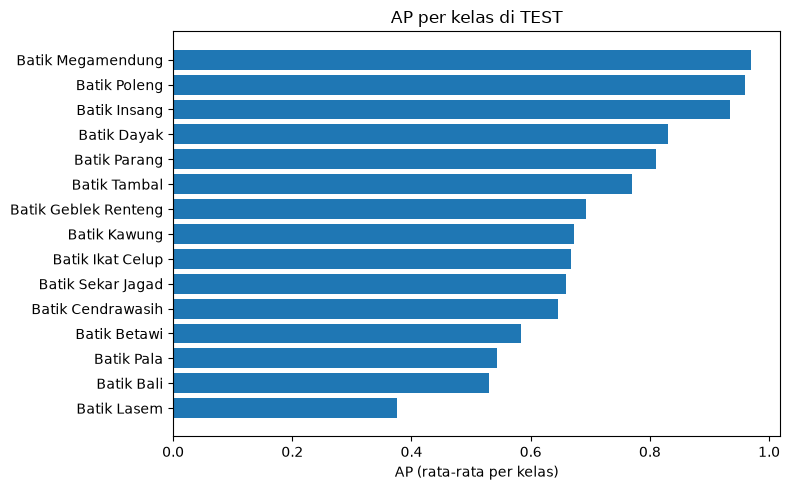

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
pc = per_class.sort_values("AP")
ax.barh(pc.index, pc["AP"])
ax.set_xlabel("AP (rata-rata per kelas)"); ax.set_title("AP per kelas di TEST")
plt.tight_layout(); plt.show()

## 8. Confusion matrix Top-1 dan pasangan yang sering tertukar

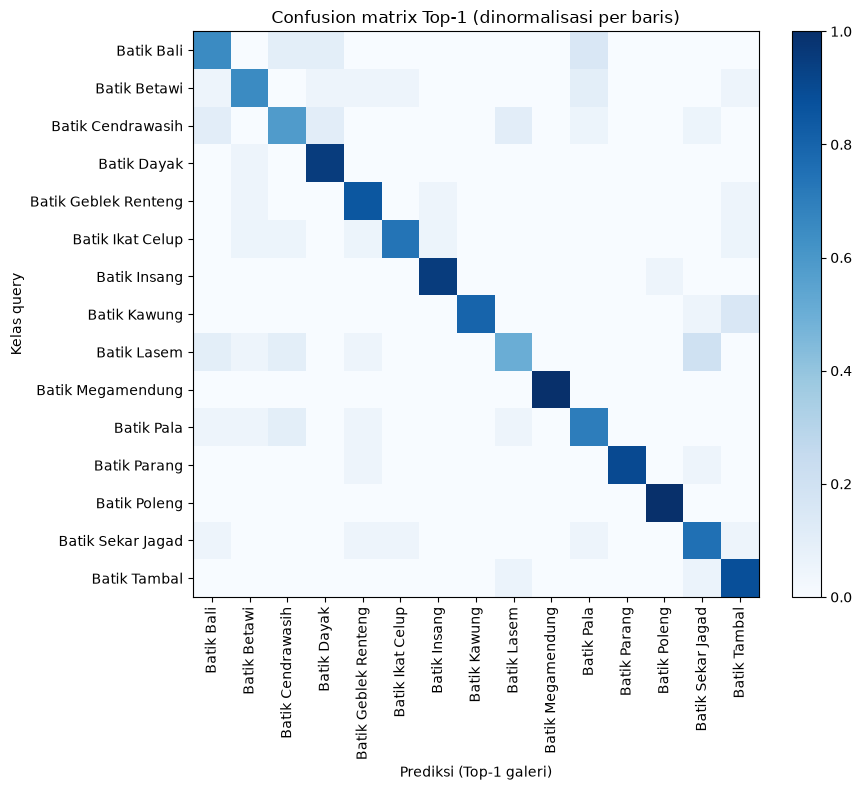

Batik Lasem -> Batik Sekar Jagad    4
Batik Bali -> Batik Pala            3
Batik Kawung -> Batik Tambal        3
Batik Bali -> Batik Dayak           2
Batik Bali -> Batik Cendrawasih     2
Batik Betawi -> Batik Pala          2
Batik Cendrawasih -> Batik Dayak    2
Batik Cendrawasih -> Batik Lasem    2
Batik Cendrawasih -> Batik Bali     2
Batik Lasem -> Batik Bali           2
Name: count, dtype: int64

In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(ql, top1_pred, labels=classes)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(classes))); ax.set_yticks(range(len(classes)))
ax.set_xticklabels(classes, rotation=90); ax.set_yticklabels(classes)
ax.set_xlabel("Prediksi (Top-1 galeri)"); ax.set_ylabel("Kelas query")
ax.set_title("Confusion matrix Top-1 (dinormalisasi per baris)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

pd.Series([f"{a} -> {b}" for a, b in zip(ql, top1_pred) if a != b]).value_counts().head(10)

## 9. Contoh query: berhasil dan gagal

P@5 sempurna: 206 query | Top-1 salah: 61 query
== Contoh berhasil ==


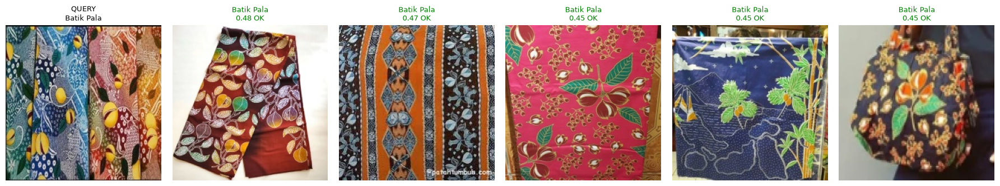

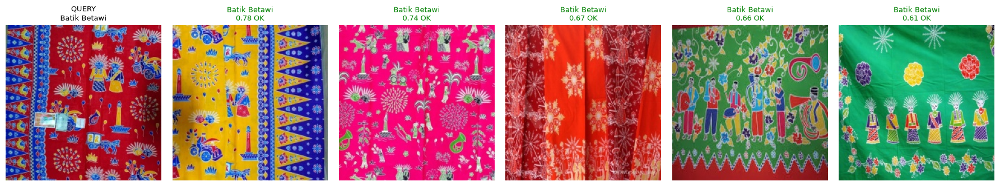

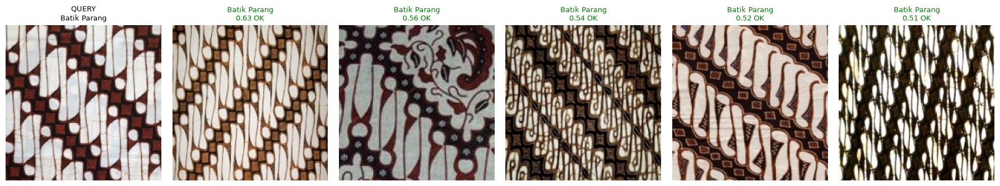

In [10]:
def show_query(i, k=5):
    s = sims[i]
    idx = np.argsort(-s)[:k]
    fig, ax = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3.2))
    ax[0].imshow(Image.open(DATA_DIR / test_df["path"][i]).convert("RGB"))
    ax[0].set_title("QUERY\n" + ql[i], fontsize=9)
    for j, gi in enumerate(idx, 1):
        ax[j].imshow(Image.open(DATA_DIR / gallery_df["path"][gi]).convert("RGB"))
        ok = gl[gi] == ql[i]
        ax[j].set_title(f"{gl[gi]}\n{s[gi]:.2f} {'OK' if ok else 'X'}", fontsize=9,
                        color="green" if ok else "red")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

rng2 = np.random.default_rng(SEED)
good = np.where(p5_q == 1.0)[0]
bad = np.where(top1_pred != ql)[0]
print(f"P@5 sempurna: {len(good)} query | Top-1 salah: {len(bad)} query")

print("== Contoh berhasil ==")
for i in rng2.choice(good, size=min(3, len(good)), replace=False):
    show_query(i)

== Contoh gagal (Top-1 salah) ==


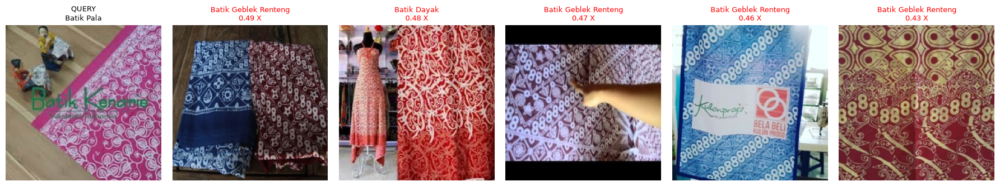

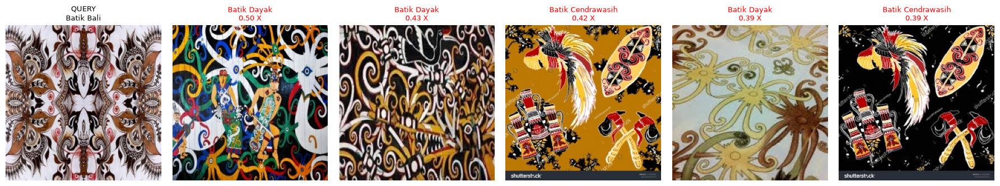

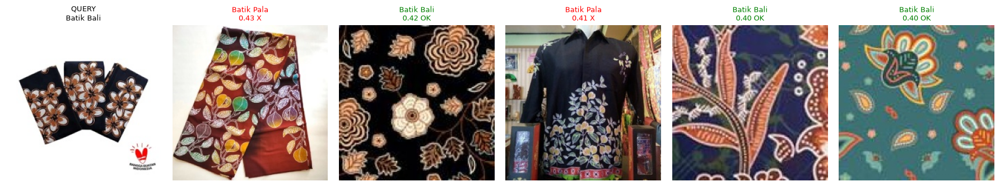

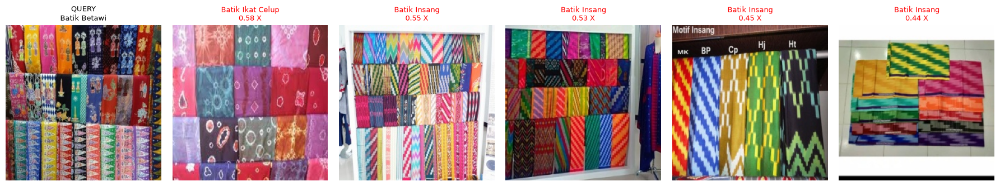

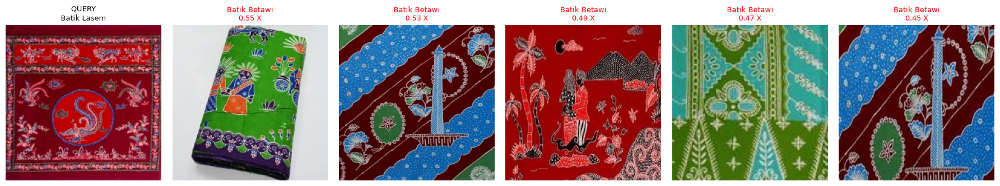

In [11]:
print("== Contoh gagal (Top-1 salah) ==")
for i in rng2.choice(bad, size=min(5, len(bad)), replace=False):
    show_query(i)

## 10. Pemeriksaan kebocoran TRAIN/TEST
Mencari pasangan TEST dan galeri dengan kemiripan kosinus sangat tinggi (kemungkinan gambar duplikat). Kalau banyak, angka TEST bisa terlalu optimis dan perlu dilaporkan atau dibersihkan.

query dengan kemiripan >= 0.99: 5 dari 295
query dengan kemiripan >= 0.98: 5 dari 295
query dengan kemiripan >= 0.95: 7 dari 295

Contoh pasangan paling mirip:


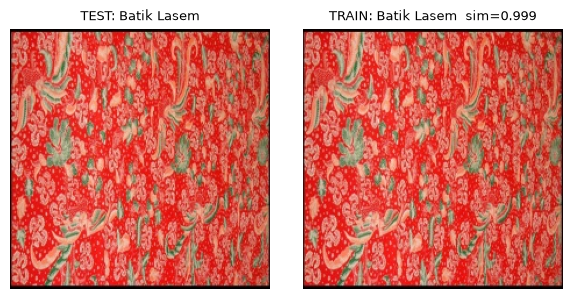

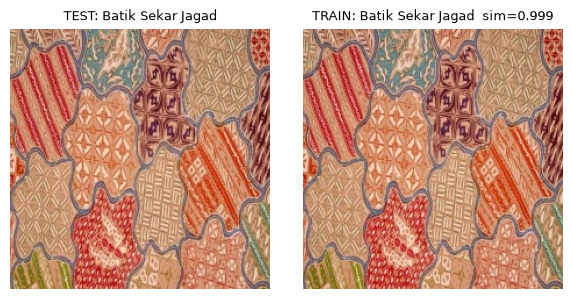

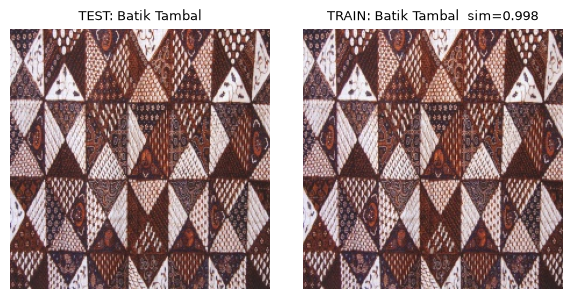

In [12]:
max_sim = sims.max(axis=1)
nn_idx = sims.argmax(axis=1)
for thr in [0.99, 0.98, 0.95]:
    print(f"query dengan kemiripan >= {thr}: {(max_sim >= thr).sum()} dari {len(max_sim)}")

dup = np.where(max_sim >= 0.98)[0]
print("\nContoh pasangan paling mirip:")
for i in np.argsort(-max_sim)[:3]:
    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    ax[0].imshow(Image.open(DATA_DIR / test_df["path"][i]).convert("RGB")); ax[0].set_title(f"TEST: {ql[i]}", fontsize=9)
    ax[1].imshow(Image.open(DATA_DIR / gallery_df["path"][nn_idx[i]]).convert("RGB")); ax[1].set_title(f"TRAIN: {gl[nn_idx[i]]}  sim={max_sim[i]:.3f}", fontsize=9)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

In [13]:
keep = max_sim < 0.98
print(f"Query dengan kemiripan >= 0.98 dibuang: {(~keep).sum()} dari {len(keep)}")
print("P@5 :", round(float(p5_q[keep].mean()), 4), "| semua query:", round(float(p5_q.mean()), 4))
print("mAP :", round(float(np.nanmean(ap_q[keep])), 4), "| semua query:", round(float(np.nanmean(ap_q)), 4))

Query dengan kemiripan >= 0.98 dibuang: 5 dari 295
P@5 : 0.7828 | semua query: 0.7864
mAP : 0.7051 | semua query: 0.7095


## 11. Ringkasan untuk laporan

### Konfigurasi dan skenario pengujian
- **Model**: EfficientNet-B0 hasil fine-tuning (`D6_eff_u4_sgd_hi`), 4 blok terakhir dibuka, optimizer SGD, learning rate 0.01 (backbone dan head), 30 epoch, dilatih pada seluruh TRAIN bersih.
- **Data**: galeri = 1.031 gambar TRAIN bersih; query = 295 gambar TEST bersih (15 kelas, 17 sampai 20 query per kelas). Data bersih berasal dari pembuangan 19 gambar TRAIN dan 5 gambar TEST yang duplikat.
- **Konsistensi**: selisih maksimum embedding galeri yang dihitung ulang terhadap `final_gallery.npy` adalah 0.0, sehingga bobot dan transformasi konsisten.

### Hasil utama di TEST (CI 95% bootstrap atas query)
| Metrik | Nilai | CI 95% |
|---|---|---|
| P@5 | 0.7864 | 0.7437 sampai 0.8251 |
| P@10 | 0.7797 | 0.7386 sampai 0.8227 |
| mAP | 0.7095 | 0.6711 sampai 0.7450 |
| Top-1 | 0.7932 | - |

### Peningkatan dari baseline ke fine-tuning
| Tahap | P@5 | P@10 | mAP |
|---|---|---|---|
| Baseline pretrained (validation) | 0.5411 | 0.4618 | 0.2716 |
| Fine-tuning D6 (validation, rata-rata 3 seed) | 0.8267 | 0.8092 | 0.7385 |
| Final (TEST, latih di seluruh TRAIN) | 0.7864 | 0.7797 | 0.7095 |

- Pada validation yang sama, fine-tuning menaikkan mAP dari 0.2716 menjadi 0.7385 (+0.467) dan P@5 dari 0.5411 menjadi 0.8267 (+0.286).
- Nilai TEST lebih rendah dari validation (mAP -0.029, P@5 -0.040). Nilai mAP validation masih berada di dalam CI TEST, tetapi P@5 validation sedikit di atas batas atas CI TEST (0.8267 vs 0.8251). Ini wajar karena konfigurasi dan epoch dipilih berdasarkan validation, sehingga angka validation sedikit optimis. Angka TEST dipakai sebagai hasil resmi.

### Kinerja per kelas (TEST)
- **Terkuat**: Megamendung (AP 0.970, Top-1 100%), Poleng (AP 0.960, Top-1 100%), Insang (AP 0.935, Top-1 95%).
- **Terlemah**: Lasem (AP 0.376, P@5 0.48, Top-1 50%), Bali (AP 0.530), Pala (AP 0.544), Betawi (AP 0.583). Cendrawasih punya Top-1 terendah (57,9%).
- Sebanyak 206 dari 295 query (69,8%) mendapat P@5 sempurna, dan 61 query (20,7%) salah di Top-1.
- Kelas dengan 17 sampai 20 query membuat angka per kelas kasar: satu query setara 5 poin.

### Pasangan kelas yang sering tertukar (Top-1)
Lasem ke Sekar Jagad (4), Bali ke Pala (3), Kawung ke Tambal (3), lalu masing-masing 2 kali: Bali ke Dayak, Bali ke Cendrawasih, Betawi ke Pala, Cendrawasih ke Dayak, Cendrawasih ke Lasem, Cendrawasih ke Bali, Lasem ke Bali.
Dugaan: kelas dengan struktur geometris atau ikonik (awan, kotak-kotak, pola tangga) mudah dipisahkan, sedangkan kelas bermotif flora atau fauna yang padat dan mirip secara visual saling tertukar. Dugaan ini perlu dicek dengan contoh gagal di bagian 9.

### Pemeriksaan duplikat dan kebocoran
- Query TEST dengan kemiripan kosinus >= 0.99 terhadap galeri: 5 dari 295 (>= 0.95: 7). Jumlahnya turun setelah pembersihan, tetapi masih ada pasangan mirip yang lolos dari deteksi SHA256 (kemungkinan hasil encode ulang).
- Dampaknya kecil: tanpa 5 query itu, P@5 menjadi 0.7828 (dari 0.7864) dan mAP 0.7051 (dari 0.7095), yaitu selisih sekitar 0.004.

### Keterbatasan
- CI selebar sekitar 8 poin karena hanya ada 295 query.
- Model final dilatih satu kali (seed 42); tiga seed hanya dipakai untuk validation.
- TEST hanya dipakai sekali setelah konfigurasi dikunci, tanpa tuning.

File yang dihasilkan: `artifacts/results_test.csv` dan `artifacts/results_test_per_class.csv`.